# Assignment 1: Motor parameter identification

I measured both drive motors of my robot (M3/E3 left wheel, M4/E4 right wheel) with the wheels spinning freely in the air, and found $\omega_{ss}$, $T_m$ and $k_e$ for each motor.

## 1. Motor model
Without the inductance, the motor is a first-order system:

$$\frac{d\omega}{dt}=\frac{U}{T_m k_e}-\frac{\omega}{T_m},\qquad \frac{d\theta}{dt}=\omega$$

**Parameters**

- $U$ [V]: the voltage on the motor. TRIK only sets PWM, so $U=\mathrm{PWM}/100\cdot U_{battery}$.
- $\theta$ [rad] and $\omega$ [rad/s]: the wheel angle from the encoder, and how fast it changes.
- $\omega_{ss}$ [rad/s]: the constant speed the motor reaches if $U$ stays the same.
- $T_m$ [s]: how fast the motor gets there. After $T_m$ it has 63 % of $\omega_{ss}$.
- $k_e$ [V·s/rad]: the volts needed for 1 rad/s of steady speed, so $\omega_{ss}=U/k_e$.

**$\theta(t)$ for a step** ($U$ constant from $t=0$, motor at rest)

- Speed: $\omega(t)=\omega_{ss}(1-e^{-t/T_m})$ with $\omega_{ss}=U/k_e$. It starts at 0, and both sides of the equation equal $\omega_{ss}e^{-t/T_m}/T_m$.
- Angle, integrating from $\theta(0)=0$:

$$\theta(t)=\int_0^t\omega_{ss}\left(1-e^{-s/T_m}\right)ds=\omega_{ss}\left(t-T_m+T_m e^{-t/T_m}\right)$$

- After a few $T_m$: $\theta\approx\omega_{ss}(t-T_m)$. The slope gives $\omega_{ss}$ and the shift gives $T_m$.

**Assumptions** (each one is tested by my data)

- No inductance: Figure 1.
- Linear viscous friction, so $\omega_{ss}\propto U$: Figure 2.
- Constant load: Figure 3 (wheels in the air).
- Constant battery voltage in a run: `battery.txt`.

## 2. Test signals
- **Step series** (`motor_steps.qrs`): 3 s off, then −100 % to +100 % in 10 % steps (0 skipped), each 2 s on and 1 s off.
- **Complex signal** (`motor_signal.qrs`, "Other"): square wave (A = 60 %, P = 1 s, 4 s), then chirp (A = 60 %, 0.2 to 3 Hz, 10 s), then 1 s off.
  - Why: the square wave gives 7 fast reversals (backlash, $T_m$ both ways), the chirp passes the corner $1/(2\pi T_m)\approx 1$ Hz (frequency response), and one run means one battery voltage.

## 3. Data collection
- TRIK Studio blocks. Every loop: read `encoder4` and `time()`, write `angle,time,PWM`, wait 5 ms.
- TRIK has no `round()`, so the chirp uses `floor(u + 0.5)`.
- For M3 only the motor, the encoder and the file name change.
- Battery read on the display before and after every run. Program A ran twice on M4 (`steps_M4_run2.txt`).

## 4. Data processing
### 4.1 Loading
- My columns are angle [deg], time [ms], PWM [%], so I changed the loading line and convert to rad and s.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy import optimize
from scipy.integrate import odeint

if not os.path.isdir('motor_data'):                                      # in Colab: upload the 6 files of motor_data/
    from google.colab import files
    os.makedirs('motor_data')
    os.chdir('motor_data')
    files.upload()
    os.chdir('..')

def load(name):                                                           # columns: angle [deg], time [ms], PWM [%]
    angle, time, pwm = np.loadtxt('motor_data/' + name, delimiter=',', unpack=True)
    return angle * np.pi / 180, time / 1000, pwm                          # SI conversion: rad, s

STEPS = {'M3': 'steps_M3.txt', 'M4': 'steps_M4.txt'}
SIGNAL = {'M3': 'signal_M3.txt', 'M4': 'signal_M4.txt'}
Ts, T = 4.0, 10.0                                                         # length of square wave and chirp [s]
bat = pd.read_csv('motor_data/battery.txt', index_col='file')
bat['U'] = (bat.U_before + bat.U_after) / 2                               # battery voltage of each run [V]
bat

,U_before,U_after,U
file,,,
steps_M4.txt,11.3,11.3,11.3
steps_M4_run2.txt,11.3,11.3,11.3
steps_M3.txt,11.3,11.3,11.3
signal_M4.txt,11.3,11.3,11.3
signal_M3.txt,11.3,11.3,11.3


### 4.2 Step responses
- Split the file where the PWM changes, and subtract the first time and angle of each step.
- Fit the course model: `curve_fit(model, t_seg, theta_seg, p0=[8, 0.1])`.
- Bounds keep $T_m>0$; without them the fit at +100 % fails.

In [2]:
def model(t, speed, T_m):
    return speed * t - speed * T_m + speed * T_m * np.exp(-t / T_m)       # angle for a step

def blocks(pwm):                                                          # (start, end) of every constant-PWM block
    cut = np.flatnonzero(np.diff(pwm)) + 1
    return list(zip(np.r_[0, cut], np.r_[cut, len(pwm)]))

def fit_steps(name):
    theta, t, pwm = load(name)
    rows = []
    for a, b in blocks(pwm):
        if pwm[a] == 0: continue                                          # motor off or coasting
        t_seg, theta_seg = t[a:b] - t[a], theta[a:b] - theta[a]           # subtract initial time and angle
        popt, pcov = optimize.curve_fit(model, t_seg, theta_seg, p0=[8, 0.1], bounds=([-50, 1e-3], [50, 2]))
        rows.append([pwm[a], *popt, *np.sqrt(np.diag(pcov))])            # w_ss, T_m and standard errors
    return pd.DataFrame(rows, columns=['PWM', 'w_ss', 'T_m', 'w_err', 'T_err']).set_index('PWM')

steps = {m: fit_steps(f) for m, f in STEPS.items()}
steps['M4 run 2'] = fit_steps('steps_M4_run2.txt')
pd.concat(steps, axis=1).round(3)

M3                           M4                      M4 run 2  \
          w_ss    T_m  w_err  T_err    w_ss    T_m  w_err  T_err     w_ss   
PWM                                                                         
-100.0 -14.502  0.025  0.005  0.000 -13.869  0.034  0.003  0.000  -13.913   
-90.0  -13.468  0.055  0.009  0.001 -12.664  0.058  0.017  0.002  -12.712   
-80.0  -12.557  0.101  0.008  0.001 -11.624  0.082  0.007  0.001  -11.707   
-70.0  -11.549  0.134  0.012  0.001 -10.529  0.117  0.008  0.001  -10.618   
-60.0  -10.578  0.146  0.013  0.001  -9.537  0.151  0.007  0.001   -9.536   
-50.0   -9.758  0.194  0.016  0.002  -8.668  0.177  0.008  0.001   -8.766   
-40.0   -8.944  0.093  0.024  0.003  -7.978  0.183  0.007  0.001   -8.057   
-30.0   -7.445  0.246  0.009  0.001  -6.552  0.244  0.007  0.001   -6.649   
-20.0   -6.142  0.035  0.010  0.002  -4.957  0.001  0.002  0.001   -5.466   
-10.0   -4.561  0.385  0.005  0.001  -3.691  0.282  0.013  0.004   -3.787   
 10.0    4.531  0.444  0.011  0.003   3.670  0.271  0.010  0.003    3.982   
 20.0    6.413  0.323  0.010  0.002   5.456  0.243  0.009  0.002    5.563   
 30.0    7.475  0.247  0.008  0.001   6.658  0.226  0.011  0.002    6.880   
 40.0    9.180  0.225  0.009  0.001   8.180  0.186  0.011  0.002    8.365   
 50.0    9.876  0.196  0.011  0.001   9.042  0.168  0.009  0.001    9.109   
 60.0   10.710  0.150  0.013  0.001   9.857  0.146  0.008  0.001    9.902   
 70.0   11.665  0.084  0.017  0.002  11.102  0.121  0.009  0.001   11.141   
 80.0   12.770  0.094  0.010  0.001  12.341  0.075  0.011  0.001   12.346   
 90.0   13.739  0.056  0.007  0.001  13.488  0.061  0.009  0.001   13.555   
 100.0  14.859  0.017  0.006  0.000  14.896  0.030  0.005  0.000   14.929   

                             
          T_m  w_err  T_err  
PWM                          
-100.0  0.033  0.004  0.000  
-90.0   0.053  0.006  0.000  
-80.0   0.088  0.006  0.001  
-70.0   0.117  0.008  0.001  
-60.0   0.145  0.010  0.001  
-50.0   0.156  0.010  0.001  
-40.0   0.197  0.010  0.001  
-30.0   0.219  0.011  0.002  
-20.0   0.275  0.010  0.002  
-10.0   0.339  0.008  0.003  
 10.0   0.294  0.007  0.002  
 20.0   0.242  0.005  0.001  
 30.0   0.226  0.008  0.001  
 40.0   0.171  0.011  0.001  
 50.0   0.163  0.009  0.001  
 60.0   0.130  0.008  0.001  
 70.0   0.114  0.009  0.001  
 80.0   0.068  0.009  0.001  
 90.0   0.058  0.008  0.001  
 100.0  0.030  0.004  0.000

**Table 1.** $\omega_{ss}$ [rad/s], $T_m$ [s] and their standard errors at every PWM level.

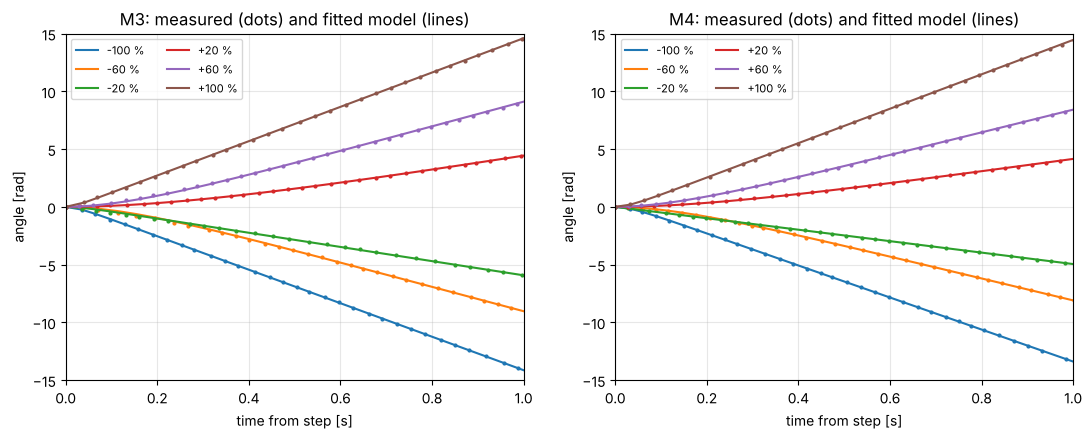

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (m, f) in zip(axs, STEPS.items()):
    theta, t, pwm = load(f)
    for a, b in blocks(pwm):
        if pwm[a] in (-100, -60, -20, 20, 60, 100):
            ts = t[a:b] - t[a]
            dots, = ax.plot(ts, theta[a:b] - theta[a], '.', ms=4)
            ax.plot(ts, model(ts, *steps[m].loc[pwm[a], ['w_ss', 'T_m']]), color=dots.get_color(), label='%+d %%' % pwm[a])
    ax.set(title=m + ': measured (dots) and fitted model (lines)', xlim=(0, 1), ylim=(-15, 15), xlabel='time from step [s]', ylabel='angle [rad]')
    ax.grid(alpha=.3)
    ax.legend(ncol=2, fontsize=8)
plt.show()

**Figure 1.** Steps at ±20, ±60 and ±100 % (first second). Dots: measured; lines: fitted model. The curves bend from the first sample, so no inductance delay is visible.

### 4.3 Speed and time constant vs PWM
- Line fit on the linear part of each direction ($20\%\le|\mathrm{PWM}|\le 80\%$), then $k_e=U_{battery}/(100\cdot\text{slope})$.
- Dead zone: the largest level at which the wheel did not move.

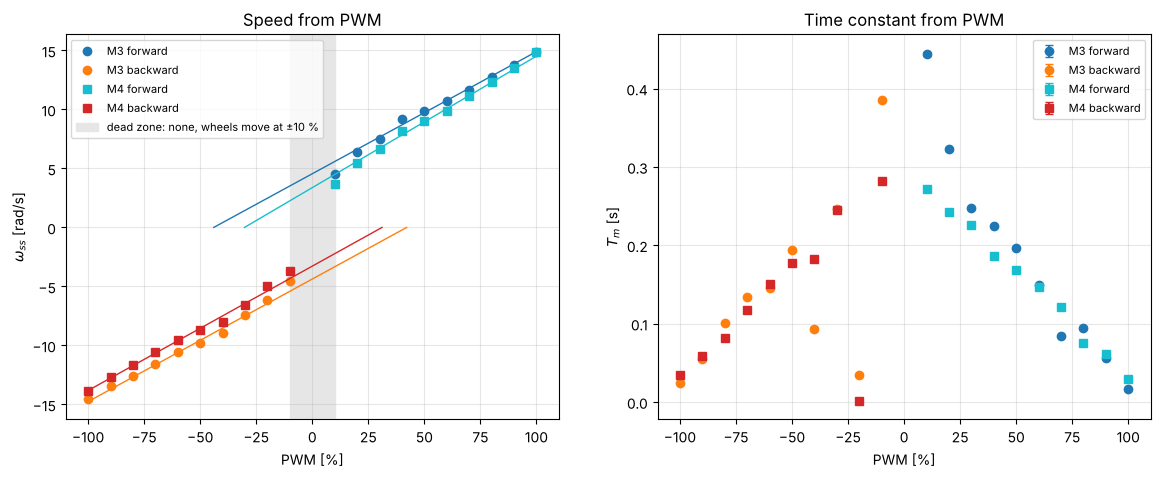

dead_zone  line_zero  slope    k_e    T_m  U_bat
M3 Forward         0.0    -43.969  0.104  1.092  0.184   11.3
   Backward        0.0    -42.094  0.104  1.088  0.141   11.3
M4 Forward         0.0    -30.253  0.111  1.014  0.153   11.3
   Backward        0.0    -31.106  0.105  1.072  0.133   11.3

In [4]:
def characteristic(m):
    d, U, out = steps[m], bat.U[STEPS[m]], {}
    for name, s in (('Forward', 1), ('Backward', -1)):
        x = d[np.sign(d.index) == s]
        lin = x[(abs(x.index) >= 20) & (abs(x.index) <= 80)]
        slope, icpt = np.polyfit(lin.index, lin.w_ss, 1)                  # w_ss = slope * PWM + icpt
        still = abs(x.index[abs(x.w_ss) < 0.5])                           # levels where the wheel did not turn
        out[name] = dict(dead_zone=still.max() if len(still) else 0, line_zero=-s * icpt / slope,
                         slope=slope, k_e=U / (100 * slope), T_m=x.T_m.mean(), U_bat=U)
    return pd.DataFrame(out).T.astype(float)

C = {m: characteristic(m) for m in STEPS}
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5))
for m, mk, cols in (('M3', 'o', ('tab:blue', 'tab:orange')), ('M4', 's', ('tab:cyan', 'tab:red'))):
    for (name, s), c in zip((('Forward', 1), ('Backward', -1)), cols):
        x, k = steps[m][np.sign(steps[m].index) == s], C[m].loc[name]
        p = np.linspace(s * k.line_zero, s * 100, 50)
        a1.plot(x.index, x.w_ss, mk, color=c, label=f'{m} {name.lower()}')
        a1.plot(p, k.slope * (p - s * k.line_zero), color=c, lw=1)
        a2.errorbar(x.index, x.T_m, x.T_err, fmt=mk, color=c, capsize=3, label=f'{m} {name.lower()}')
a1.axvspan(-10, 10, color='0.9', label='dead zone: none, wheels move at ±10 %')
a1.set(title='Speed from PWM', xlabel='PWM [%]', ylabel=r'$\omega_{ss}$ [rad/s]')
a2.set(title='Time constant from PWM', xlabel='PWM [%]', ylabel=r'$T_m$ [s]')
for a in (a1, a2):
    a.grid(alpha=.3)
    a.legend(fontsize=8)
plt.show()
pd.concat(C).round(3)

**Figure 2 (left).** $\omega_{ss}$ vs PWM with the line of each direction. Grey: where a dead zone would be; both wheels already move at ±10 %.

**Figure 3 (right).** $T_m$ vs PWM with error bars. $T_m$ is **not constant**.

**Table 2.** For each direction: dead zone, PWM where the line reaches zero speed, slope, $k_e$, mean $T_m$, battery voltage.

### 4.4 Complex signal: model vs real motor
- `odeint` with the recorded PWM (`u = np.interp(t, t_log, U_log)`) and the mean $k_e$, $T_m$ of each motor.
- **Model A** (no dead zone): $\omega_{ss}=U/k_e$.
- **Model B** (with dead zone): $\omega_{ss}=(|U|-U_0)/k_e$ with the sign of $U$, the line of Figure 2. On my motors $U_0<0$, so it is an offset, not a dead zone.
- Measured speed: `np.gradient` of the angle, then a moving average of 3 samples (about 0.15 s).

In [5]:
def simulate(m, wss):
    theta, t, pwm = load(SIGNAL[m])
    t_log, U_log, T_m = t - t[0], pwm / 100 * bat.U[SIGNAL[m]], C[m].T_m.mean()
    def motor(state, t):
        speed, angle = state
        u = np.interp(t, t_log, U_log)                                     # recorded input, converted to volts
        return np.array([-speed / T_m + wss(u) / T_m, speed])            # model A: wss(u) = u / k_e
    return odeint(motor, [0, 0], t_log, hmax=0.005)                       # y[:,0] speed, y[:,1] angle

A, B = 'A: without dead zone', 'B: with dead zone'
fit = lambda y, yh: 100 * (1 - np.linalg.norm(y - yh) / np.linalg.norm(y - np.mean(y)))
rmse = lambda y, yh: np.sqrt(np.mean((y - yh) ** 2))
meas, sims, rows = {}, {}, []
for m in SIGNAL:
    k, U0 = C[m].k_e.mean(), (C[m].line_zero / 100 * C[m].U_bat).mean()
    theta, t, pwm = load(SIGNAL[m])
    w = pd.Series(np.gradient(theta, t)).rolling(3, center=True, min_periods=1).mean().values   # measured speed
    meas[m] = (t - t[0], theta - theta[0], w, pwm)
    for name, wss in ((A, lambda u: u / k), (B, lambda u: np.sign(u) * max(abs(u) - U0, 0) / k)):
        y = sims[m, name] = simulate(m, wss)
        rows.append([m, name, fit(theta - theta[0], y[:, 1]), fit(w, y[:, 0]), rmse(theta - theta[0], y[:, 1]), rmse(w, y[:, 0])])
pd.DataFrame(rows, columns=['motor', 'model', 'fit angle %', 'fit speed %', 'RMSE angle [rad]', 'RMSE speed [rad/s]']).set_index(['motor', 'model']).round(2)

fit angle %  fit speed %  RMSE angle [rad]  \
motor model                                                              
M3    A: without dead zone       -54.19        57.84              5.12   
      B: with dead zone           53.50        75.91              1.54   
M4    A: without dead zone       -48.20        64.33              4.42   
      B: with dead zone           36.05        74.59              1.91   

                            RMSE speed [rad/s]  
motor model                                     
M3    A: without dead zone                2.01  
      B: with dead zone                   1.15  
M4    A: without dead zone                1.65  
      B: with dead zone                   1.18

**Table 3.** Fit $=100\,(1-\|y-\hat y\|/\|y-\bar y\|)$ and RMSE of angle and speed on the complex signal.

M3 model B speed fit, square wave: 87.3 %
M3 model B speed fit, chirp: 69.3 %
M4 model B speed fit, square wave: 86.1 %
M4 model B speed fit, chirp: 67.7 %


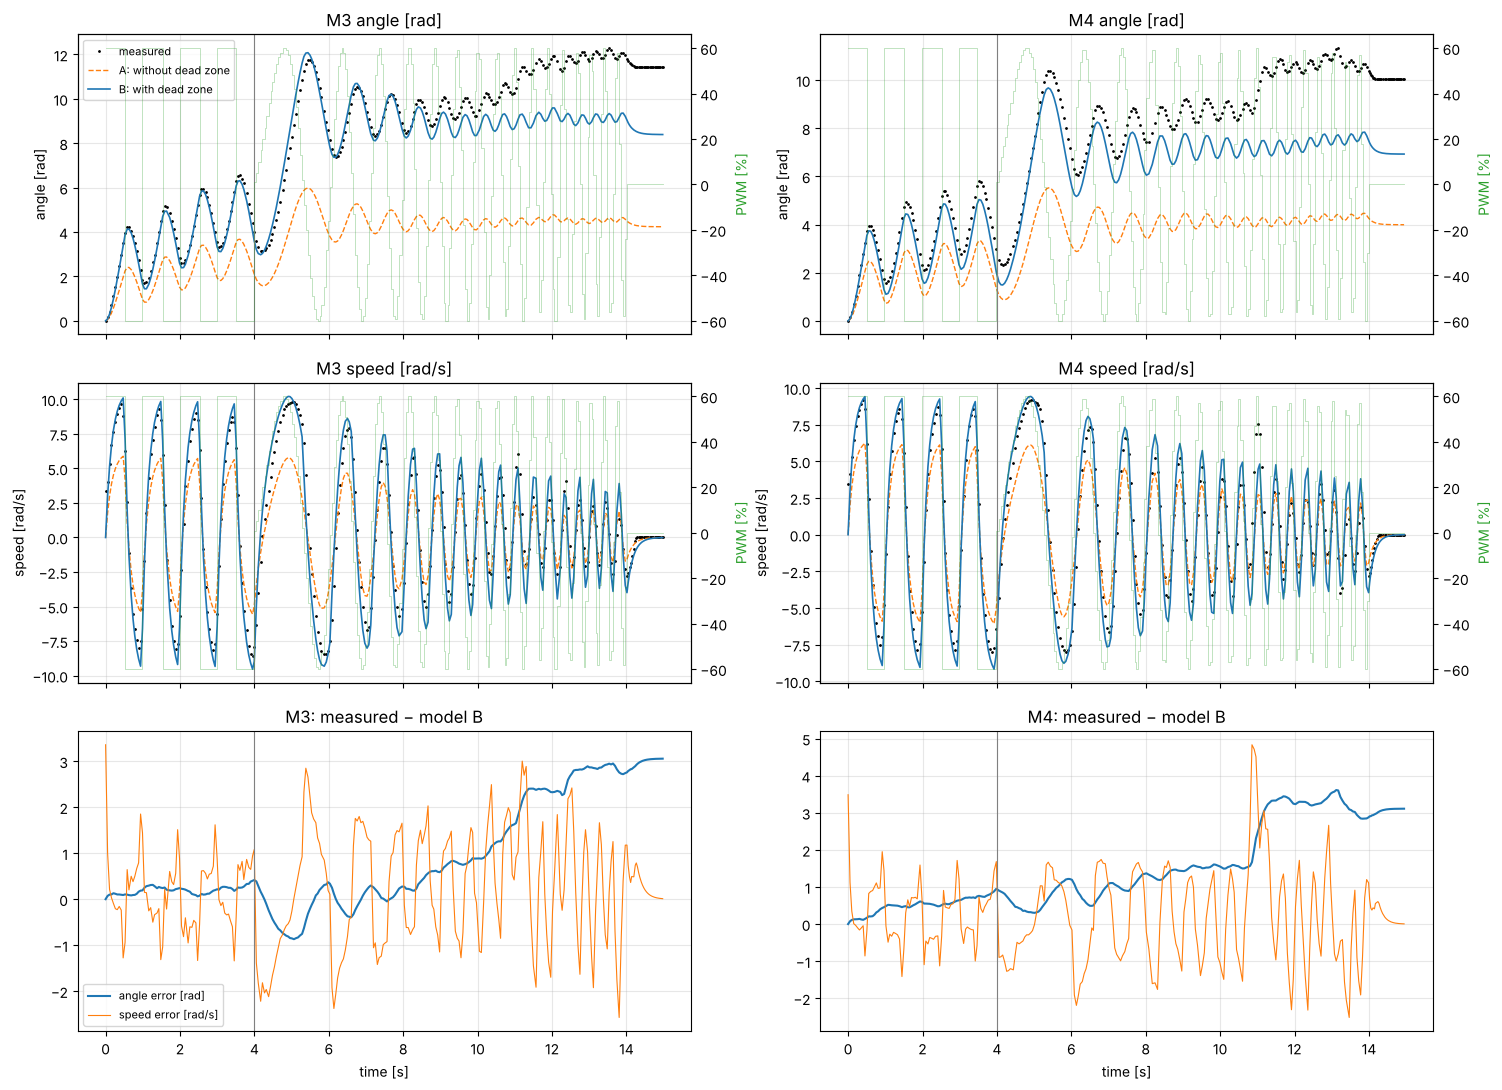

In [6]:
fig, axs = plt.subplots(3, 2, figsize=(15, 11), sharex=True)
for j, m in enumerate(SIGNAL):
    tt, th, w, pwm = meas[m]
    for i, (y, k, name) in enumerate(((th, 1, 'angle [rad]'), (w, 0, 'speed [rad/s]'))):   # row 1 angle, row 2 speed
        ax = axs[i, j]
        ax.plot(tt, y, 'k.', ms=2, label='measured')
        ax.plot(tt, sims[m, A][:, k], '--', color='tab:orange', lw=1, label=A)
        ax.plot(tt, sims[m, B][:, k], color='tab:blue', lw=1.2, label=B)
        ax.set(title=f'{m} {name}', ylabel=name)
        ax2 = ax.twinx()                                                  # input PWM on a second axis
        ax2.step(tt, pwm, where='post', color='tab:green', lw=.6, alpha=.35)
        ax2.set_ylabel('PWM [%]', color='tab:green')
    axs[2, j].plot(tt, th - sims[m, B][:, 1], label='angle error [rad]')  # row 3: error of model B
    axs[2, j].plot(tt, w - sims[m, B][:, 0], lw=.8, label='speed error [rad/s]')
    axs[2, j].set(title=f'{m}: measured − model B', xlabel='time [s]')
    for part, s in (('square wave', tt < Ts), ('chirp', (tt >= Ts) & (tt < Ts + T))):
        print(f'{m} model B speed fit, {part}: {fit(w[s], sims[m, B][s, 0]):.1f} %')
for ax in axs.flat:
    ax.axvline(Ts, color='0.5', lw=.8)                                    # square wave ends, chirp starts
    ax.grid(alpha=.3)
axs[0, 0].legend(fontsize=8, loc='upper left')
axs[2, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Figure 4 (rows 1 and 2).** Measured and simulated angle and speed, with the PWM on the second axis.

**Figure 5 (row 3).** Error of model B over time. Grey line: the square wave ends and the chirp starts.

**Chirp**
- For every full chirp period: speed swing divided by voltage swing.
- Compared with the formula $1/(k_e\sqrt{1+(2\pi fT_m)^2})$.

M3: corner frequency 1/(2 pi T_m) = 0.98 Hz
M4: corner frequency 1/(2 pi T_m) = 1.11 Hz


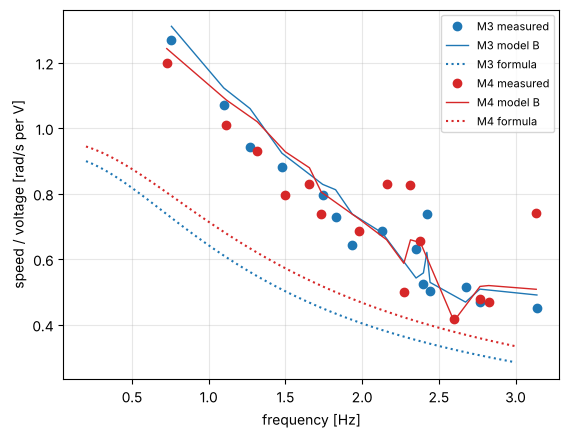

In [7]:
def ratio(m, angle):                                                      # speed swing / voltage swing per input period
    tt, th, w, pwm = meas[m]
    U, w = pwm / 100 * bat.U[SIGNAL[m]], np.gradient(angle, tt)
    z = np.flatnonzero((np.diff(U >= 0) != 0) & (tt[1:] > Ts) & (tt[1:] < Ts + T))   # zero crossings of the input
    r = np.array([[1 / (tt[j] - tt[i]), np.ptp(w[i:j]) / np.ptp(U[i:j])] for i, j in zip(z[:-2:2], z[2::2])])
    return r[np.argsort(r[:, 0])].T

f = np.linspace(0.2, 3, 100)
for m, c in zip(SIGNAL, ('tab:blue', 'tab:red')):
    plt.plot(*ratio(m, meas[m][1]), 'o', color=c, label=m + ' measured')
    plt.plot(*ratio(m, sims[m, B][:, 1]), '-', color=c, lw=1, label=m + ' model B')
    plt.plot(f, 1 / (C[m].k_e.mean() * np.sqrt(1 + (2 * np.pi * f * C[m].T_m.mean()) ** 2)), ':', color=c, label=m + ' formula')
    print(f'{m}: corner frequency 1/(2 pi T_m) = {1 / (2 * np.pi * C[m].T_m.mean()):.2f} Hz')
plt.xlabel('frequency [Hz]')
plt.ylabel('speed / voltage [rad/s per V]')
plt.grid(alpha=.3)
plt.legend(fontsize=8)
plt.show()

**Figure 4b.** Chirp: speed amplitude divided by input amplitude vs frequency. Dots: measured; solid: model B; dotted: formula.

## 5. Artifact analysis

In [8]:
pct = lambda a, b: 100 * (a / b - 1)                                      # difference in %

# forward vs backward, and saturation (speed at ±100 % compared with the line)
for m in STEPS:
    F, Bk = C[m].loc['Forward'], C[m].loc['Backward']
    sat_f = pct(steps[m].w_ss[100], F.slope * (100 - F.line_zero))
    sat_b = pct(steps[m].w_ss[-100], -Bk.slope * (100 - Bk.line_zero))
    print(f'{m} forward vs backward: slope {pct(F.slope, Bk.slope):+.1f} %, T_m {pct(F.T_m, Bk.T_m):+.1f} %; '
          f'speed at +100 / -100 % is {sat_f:+.1f} / {sat_b:+.1f} % off the line')

# motor-to-motor spread
F3, F4 = C['M3'].loc['Forward'], C['M4'].loc['Forward']
print(f'M3 vs M4: slope {pct(F3.slope, F4.slope):+.1f} %, k_e {pct(F3.k_e, F4.k_e):+.1f} %, T_m {pct(F3.T_m, F4.T_m):+.1f} %')

# zero drift: encoder in the first 3 s (motor off), first and last angle, first time()
for f in [*STEPS.values(), 'steps_M4_run2.txt']:
    theta, t, pwm = load(f)
    off = t - t[0] < 3
    print(f'{f}: change with motor off {np.degrees(np.ptp(theta[off])):.0f} deg, '
          f'first / last angle {np.degrees(theta[0]):.0f} / {np.degrees(theta[-1]):.0f} deg, first time() {1000 * t[0]:.0f} ms')

# coasting: angle turned in the 1 s after each step, compared with the model w_ss * T_m
coast = []
for m, f in STEPS.items():
    theta, t, pwm = load(f)
    bl = blocks(pwm)
    for (a, b), (c, d) in zip(bl, bl[1:]):
        if pwm[a] != 0 and pwm[c] == 0:                                   # a step, then its coasting block
            coast.append([m, abs(steps[m].w_ss[pwm[a]]) * C[m].T_m.mean(), abs(theta[d - 1] - theta[c])])
coast = pd.DataFrame(coast, columns=['motor', 'model', 'measured'])
print(f'coasting {coast.measured.min():.1f} to {coast.measured.max():.1f} rad; measured / model:',
      (coast.measured / coast.model).groupby(coast.motor).median().round(2).to_dict())

# sampling interval
dt = {f: np.diff(load(f)[1]) * 1000 for f in [*STEPS.values(), 'steps_M4_run2.txt', *SIGNAL.values()]}
for f, d in dt.items():
    print(f'{f}: sampling interval mean {d.mean():.1f} ms, min {d.min():.0f}, max {d.max():.0f}')

# battery sag
print('largest battery drop in a run:', (bat.U_before - bat.U_after).max(), 'V')
print(f'repeat run: w_ss of run 2 / run 1 = {(steps["M4 run 2"].w_ss / steps["M4"].w_ss).mean():.3f}')

# encoder noise: speed in the steady part of +60 % (M4)
theta, t, pwm = load('steps_M4.txt')
s = (pwm == 60) & (t > t[pwm == 60][0] + 1)
w_raw = np.gradient(theta[s], t[s])
w_avg = np.convolve(w_raw, np.ones(3) / 3, 'valid')
print(f'speed noise at +60 %: raw {w_raw.std():.2f} rad/s, moving average of 3: {w_avg.std():.2f} rad/s')

# event at about 11 s in the complex signal
for m in SIGNAL:
    tt, th, w, pwm = meas[m]
    e = th - sims[m, B][:, 1]
    k = (tt > 10.6) & (tt < 11.6)
    print(f'{m}: angle error grows by {e[k][-1] - e[k][0]:+.2f} rad between 10.6 and 11.6 s')

M3 forward vs backward: slope -0.4 %, T_m +29.8 %; speed at +100 / -100 % is -0.3 / -1.8 % off the line
M4 forward vs backward: slope +5.8 %, T_m +14.8 %; speed at +100 / -100 % is +2.6 / +0.4 % off the line
M3 vs M4: slope -7.2 %, k_e +7.7 %, T_m +20.3 %
steps_M3.txt: change with motor off 0 deg, first / last angle 5272 / 5377 deg, first time() 42 ms
steps_M4.txt: change with motor off 0 deg, first / last angle 6572 / 7187 deg, first time() 44 ms
steps_M4_run2.txt: change with motor off 0 deg, first / last angle 7187 / 7950 deg, first time() 46 ms
coasting 0.2 to 5.5 rad; measured / model: {'M3': 1.82, 'M4': 1.45}
steps_M3.txt: sampling interval mean 33.1 ms, min 25, max 77
steps_M4.txt: sampling interval mean 31.8 ms, min 23, max 94
steps_M4_run2.txt: sampling interval mean 32.5 ms, min 24, max 60
signal_M3.txt: sampling interval mean 51.6 ms, min 28, max 83
signal_M4.txt: sampling interval mean 51.4 ms, min 26, max 92
largest battery drop in a run: 0.0 V
repeat run: w_ss of run 2 / 

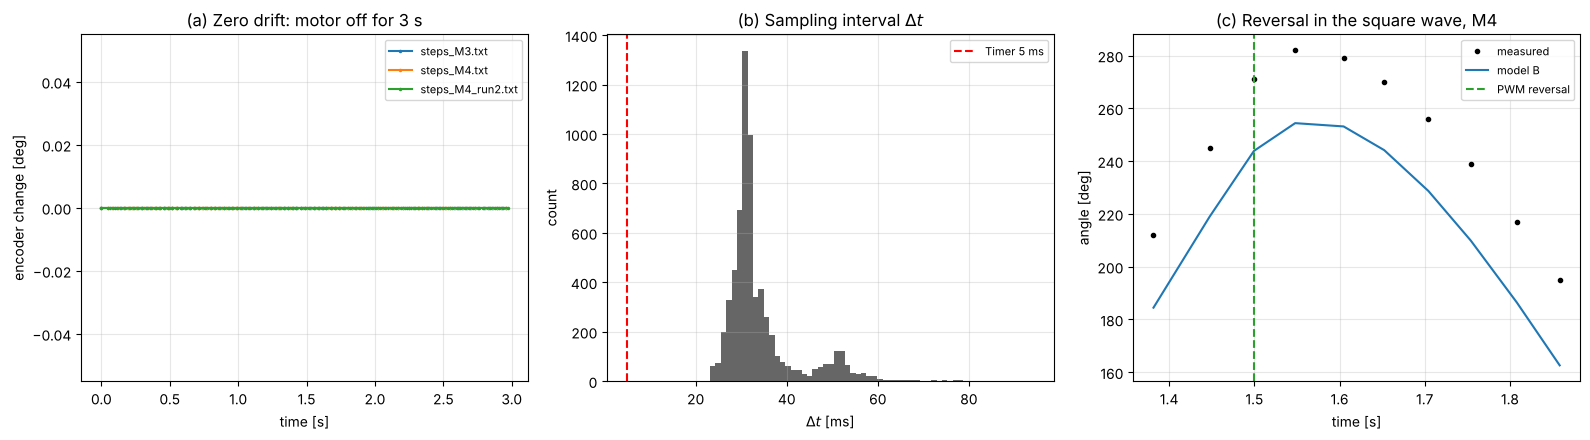

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))

for f in [*STEPS.values(), 'steps_M4_run2.txt']:                          # (a) zero drift
    theta, t, pwm = load(f)
    off = t - t[0] < 3
    ax[0].plot(t[off] - t[0], np.degrees(theta[off] - theta[0]), '.-', ms=3, label=f)
ax[0].set(title='(a) Zero drift: motor off for 3 s', xlabel='time [s]', ylabel='encoder change [deg]')

ax[1].hist(np.concatenate(list(dt.values())), bins=60, color='0.4')      # (b) sampling interval
ax[1].axvline(5, color='r', ls='--', label='Timer 5 ms')
ax[1].set(title=r'(b) Sampling interval $\Delta t$', xlabel=r'$\Delta t$ [ms]', ylabel='count')

tt, th, w, pwm = meas['M4']                                               # (c) third reversal of the square wave
i = np.flatnonzero((np.diff(np.sign(pwm)) != 0) & (tt[1:] < Ts))[2] + 1
z = (tt > tt[i] - .15) & (tt < tt[i] + .4)
ax[2].plot(tt[z], np.degrees(th[z]), 'k.', label='measured')
ax[2].plot(tt[z], np.degrees(sims['M4', B][z, 1]), label='model B')
ax[2].axvline(tt[i], color='tab:green', ls='--', label='PWM reversal')
ax[2].set(title='(c) Reversal in the square wave, M4', xlabel='time [s]', ylabel='angle [deg]')

for a in ax:
    a.grid(alpha=.3)
    a.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Figure 6.** (a) encoder in the first 3 s with the motor off, (b) histogram of the real sampling interval, (c) one square-wave reversal of M4.

- **Forward vs backward:** slope −0.4 % (M3) and +5.8 % (M4); dead zone 0 % both ways (Table 2); $T_m$ +30 % and +15 % forward, partly from single low backward fits (−20 %, −40 %).
  - *Cause:* brushes and gears are not perfectly symmetric.
- **Zero drift:** 0° with the motor off (Figure 6a). The count is not reset between programs (`steps_M4` ends at 7187°, run 2 starts there), and `time()` is 42 to 46 ms at the first sample.
  - *Cause:* the encoder counts only when the shaft turns, so I measure every step from its own first sample.
- **Dead zone:** none, both wheels turn at ±10 %; the lines reach zero at −30 % (M4) and −44 % (M3).
  - *Cause:* little friction with the wheels in the air; below 10 % my steps cannot see it.
- **Saturation:** none, at ±100 % the speed is within 3 % of the line.
  - *Cause:* the battery and driver give full voltage.
- **Coasting:** 0.2 to 5.5 rad after power-off, 1.5 (M4) to 1.8 (M3) times the model $\omega_{ss}T_m$.
  - *Cause:* at power 0 the motor is braked less than the model assumes.
- **Gear backlash:** no flat part at the reversal (Figure 6c).
  - *Cause:* the play is smaller than one encoder count (1°).
- **Sampling jitter:** 5 ms Timer, but 32 to 33 ms (steps) and 51 to 52 ms (signal) on average, from 23 to 94 ms (Figure 6b). With 5 ms the speeds would be 6 to 10 times too big.
  - *Cause:* Write To File and the scheduler take a different time every loop; the signal loop has more blocks.
- **Battery sag:** 11.3 V before and after every run, so the drop is below the 0.1 V display step; run 2 matches run 1 within 2 %.
  - *Cause:* free wheels draw little current and the runs are short.
- **Encoder noise:** speed noise at +60 % is 0.28 rad/s raw and 0.18 rad/s with the 3-sample average.
  - *Cause:* the encoder counts whole degrees, and `np.gradient` divides them by a short $\Delta t$.
- **Motor-to-motor spread:** M3 vs M4: slope −7 %, $k_e$ +8 %, $T_m$ +20 %; at +50 %, 9.88 vs 9.04 rad/s (Table 1).
  - *Cause:* the motors are not identical, and M3 drives the bigger wheel (more inertia).
- **Other, event at 11 s:** in both signal runs the angle error jumps by 1.1 (M3) and 1.9 rad (M4) between 10.6 and 11.6 s.
  - *Cause:* unknown; it is at the same point of the signal for both motors.

## Report
### 1. Estimated values

In [10]:
names = {'dead_zone': 'Dead zone, % PWM', 'slope': 'Slope, rad/s per % PWM', 'k_e': 'k_e, V·s/rad', 'T_m': 'Mean T_m, s', 'U_bat': 'U_battery, V'}
for m in C:
    print('Motor', m, '(left wheel)' if m == 'M3' else '(right wheel)')
    display(C[m][list(names)].rename(columns=names).round(3))

Motor M3 (left wheel)


,"Dead zone, % PWM","Slope, rad/s per % PWM","k_e, V·s/rad","Mean T_m, s","U_battery, V"
Forward,0.0,0.104,1.092,0.184,11.3
Backward,0.0,0.104,1.088,0.141,11.3


Motor M4 (right wheel)


,"Dead zone, % PWM","Slope, rad/s per % PWM","k_e, V·s/rad","Mean T_m, s","U_battery, V"
Forward,0.0,0.111,1.014,0.153,11.3
Backward,0.0,0.105,1.072,0.133,11.3


### 2. Required plots
Figures 1 to 6 above, each with its caption.

### 3. Analysis

**How well does the first-order model describe the motor?**

Each step fits well (Figure 1), but the parameters are not constant: $T_m$ falls from 0.27 to 0.44 s at ±10 % to 0.02 to 0.03 s at ±100 % (Figure 3), and the speed lines reach zero at −30 % and −44 % instead of 0 (Figure 2). So linear friction fails, while the other three assumptions hold. A likely cause is the PWM driver: in the off part of each PWM period the motor is not driven, so at low PWM it is faster and less braked than $U=\mathrm{PWM}/100\cdot U_{battery}$ suggests. On the complex signal the speed fit is 58 % (M3) and 64 % (M4) for model A, and 76 % and 75 % for model B, or 87 % and 86 % on the square wave alone (Table 3). The error is largest in the chirp (69 % and 68 %), which passes through all PWM levels while the model uses one mean $T_m$, and at 11 s (Figure 5).

**Forward vs backward: one set of parameters or two?**

The slopes differ by only 0.4 % (M3) and 6 % (M4), and neither direction has a dead zone. The 15 to 30 % difference in $T_m$ comes partly from single low backward fits. So both directions behave as the same motor, and a controller can use **one set per motor**. The two motors differ more (7 % in slope), so each motor needs its own set.

**Which artifacts matter for odometry?**

Section 5 lists all 11 with their size. For odometry the important ones are the real sampling interval (32 to 52 ms with jitter, so always use the logged time, never 5 ms), the 1° encoder step, and coasting, because the robot keeps rolling after the motors stop. The encoder itself is reliable: no drift and no visible backlash. The motor spread (M3 about 9 % faster) does not change odometry, which measures real wheel angles, but it makes the robot leave its path.

**Which complex signal, and what did it show?**

A square wave, then a chirp. The square wave gave 7 fast reversals with no flat part, so there is no backlash above 1°. The chirp showed the frequency response, which steps cannot: the speed-to-voltage ratio falls from about 1.2 to 0.45 (rad/s)/V between 0.7 and 3 Hz, with a corner near 1 Hz as a first-order system should (Figure 4b). It lies above the formula for the same reason model A is too slow, and model B follows it. The chirp also revealed the event at 11 s.